# Expert Challenge — Sistemas Especialistas
**UNOESC · Inteligência Artificial · Equipe 404 AI**

## Missão
Construir e avaliar um sistema especialista baseado em regras explícitas para classificar flores do Iris Dataset.

**Importante:** você não vai treinar um modelo de Machine Learning. Você vai formular regras, implementá-las, testar e explicar seus resultados.

---
**Resumo da solução:** sistema especialista com **base de conhecimento em dois níveis** (regras de abstração → regras de classificação), **motor de inferência com encadeamento progressivo** (*forward chaining*), **fatores de certeza** para resolver conflitos, **regras de contingência** para fatos incompletos, **validação de fatos** e **explicação completa** de cada decisão.

## 1. Conheça o problema

O Iris contém 150 amostras, quatro atributos numéricos e três classes: `setosa`, `versicolor` e `virginica`.

Cada exemplo possui quatro atributos:
- comprimento da sépala (`sepal length (cm)`);
- largura da sépala (`sepal width (cm)`);
- comprimento da pétala (`petal length (cm)`);
- largura da pétala (`petal width (cm)`).

**Antes de programar, discuta com sua equipe:**
1. Quais atributos parecem mais úteis?
2. Como representarão o conhecimento?
3. O que acontece se nenhuma regra se aplicar?
4. O que acontece se regras diferentes indicarem classes diferentes?

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns=["target"])
class_names = list(iris.target_names)
feature_cols = list(iris.feature_names)

# Bibliotecas adicionais usadas pela equipe (apenas para análise e gráficos)
import copy
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

In [2]:
# Explore o tamanho da base, os atributos e a distribuição das classes
print("Formato:", df.shape)
print("\nClasses:", class_names)
print("\nAtributos:", feature_cols)

print("\nAmostras por classe:")
print(df["species"].value_counts())
print("\n")

df

Formato: (150, 5)

Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Atributos: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Amostras por classe:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64




,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


### 1.1 Separação treino/teste **antes** de criar as regras

Para que a avaliação seja honesta, a divisão oficial (`test_size=0.3`, `random_state=42`, estratificada) é feita **antes** da análise exploratória.
**Todas as regras, limiares e fatores de certeza foram obtidos olhando somente o conjunto de treino (105 flores).** As 45 flores de teste só são usadas na avaliação (seção 5).

In [3]:
treino, teste = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df["species"]
)
PL, PW = "petal length (cm)", "petal width (cm)"
SL, SW = "sepal length (cm)", "sepal width (cm)"

print("Treino:", treino.shape, "| Teste:", teste.shape)
print(treino["species"].value_counts().to_dict())

# Estatísticas por espécie (somente treino)
treino.groupby("species")[feature_cols].agg(["min", "mean", "max"]).round(2).T

Treino: (105, 5) | Teste: (45, 5)
{'versicolor': 35, 'setosa': 35, 'virginica': 35}


species                 setosa  versicolor  virginica
sepal length (cm) min     4.30        5.00       5.60
                  mean    4.99        5.95       6.68
                  max     5.70        7.00       7.90
sepal width (cm)  min     2.30        2.00       2.20
                  mean    3.43        2.73       3.01
                  max     4.40        3.20       3.80
petal length (cm) min     1.10        3.00       4.80
                  mean    1.49        4.24       5.63
                  max     1.90        5.10       6.90
petal width (cm)  min     0.10        1.00       1.50
                  mean    0.24        1.31       2.07
                  max     0.40        1.80       2.50

In [4]:
# Quanto cada atributo "mistura" as classes? (faixa de sobreposição no treino)
def sobreposicao(dados, atributo, classe_a, classe_b):
    a = dados.loc[dados["species"] == classe_a, atributo]
    b = dados.loc[dados["species"] == classe_b, atributo]
    lo, hi = max(a.min(), b.min()), min(a.max(), b.max())
    if lo > hi:
        return "sem sobreposição", 0
    n = int(((a >= lo) & (a <= hi)).sum() + ((b >= lo) & (b <= hi)).sum())
    return f"[{lo:.1f}, {hi:.1f}]", n

linhas = []
for atributo in feature_cols:
    for ca, cb in [("setosa", "versicolor"), ("versicolor", "virginica")]:
        faixa, n = sobreposicao(treino, atributo, ca, cb)
        linhas.append({"atributo": atributo, "par de classes": f"{ca} x {cb}",
                       "faixa de sobreposição": faixa, "flores na faixa (de 70)": n})
pd.DataFrame(linhas)

,atributo,par de classes,faixa de sobreposição,flores na faixa (de 70)
0,sepal length (cm),setosa x versicolor,"[5.0, 5.7]",33
1,sepal length (cm),versicolor x virginica,"[5.6, 7.0]",52
2,sepal width (cm),setosa x versicolor,"[2.3, 3.2]",45
3,sepal width (cm),versicolor x virginica,"[2.2, 3.2]",62
4,petal length (cm),setosa x versicolor,sem sobreposição,0
5,petal length (cm),versicolor x virginica,"[4.8, 5.1]",16
6,petal width (cm),setosa x versicolor,sem sobreposição,0
7,petal width (cm),versicolor x virginica,"[1.5, 1.8]",17


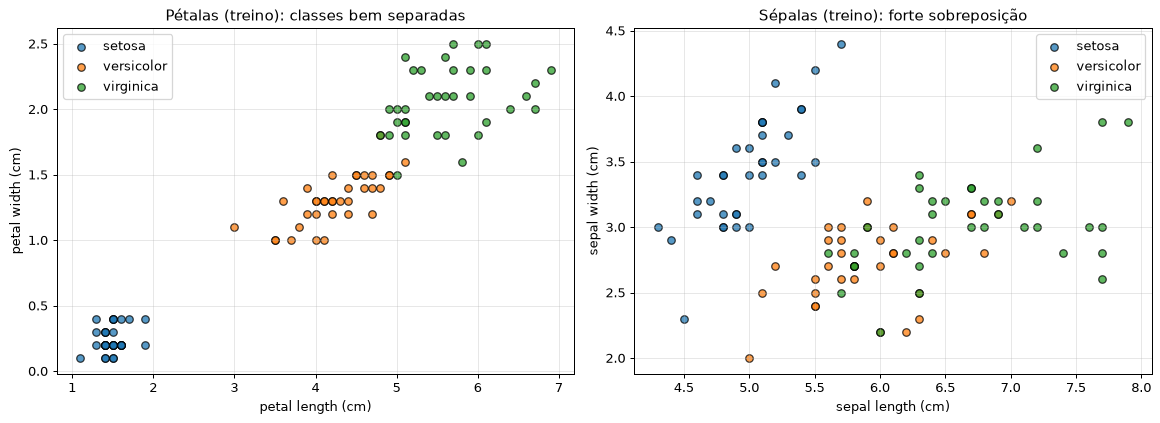

In [5]:
cores = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for especie, g in treino.groupby("species"):
    axes[0].scatter(g[PL], g[PW], c=cores[especie], label=especie, alpha=.75, edgecolor="k")
    axes[1].scatter(g[SL], g[SW], c=cores[especie], label=especie, alpha=.75, edgecolor="k")
axes[0].set(xlabel=PL, ylabel=PW, title="Pétalas (treino): classes bem separadas")
axes[1].set(xlabel=SL, ylabel=SW, title="Sépalas (treino): forte sobreposição")
for ax in axes:
    ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 1.2 Respostas da equipe às perguntas iniciais

1. **Atributos mais úteis:** as **pétalas**. No treino, `setosa` é separada das demais sem nenhuma sobreposição tanto pelo comprimento (máx. 1,9 cm contra mín. 3,0 cm) quanto pela largura da pétala (máx. 0,4 cm contra mín. 1,0 cm). Entre `versicolor` e `virginica` a sobreposição existe, mas é pequena (comprimento entre 4,8 e 5,1 cm; largura entre 1,5 e 1,8 cm). As **sépalas** se sobrepõem muito (dezenas de flores na faixa de mistura), por isso foram usadas apenas como **conhecimento de contingência**, quando faltam os dados das pétalas.
2. **Representação do conhecimento:** *fatos* = pares `atributo → valor` (memória de trabalho); *regras* = estruturas `SE condições ENTÃO conclusão` com identificador, descrição em linguagem natural e **fator de certeza (CF)**. Há regras de **abstração** (número → conceito qualitativo, ex.: "pétala longa") e regras de **classificação** (conceito → espécie).
3. **Nenhuma regra se aplica:** o sistema **não chuta**: responde `"inconclusivo"` e informa o motivo (ex.: fatos ausentes ou fora do domínio).
4. **Regras indicam classes diferentes:** as evidências de cada classe são combinadas pelo método dos fatores de certeza (MYCIN) e vence a classe com maior certeza. Evidências **contraditórias** (setosa e virginica ao mesmo tempo, combinação nunca observada) geram `"inconclusivo"`.

## 2. Projetar a arquitetura

Descrevam a representação dos fatos, a estrutura da base de conhecimento, o motor de inferência, a política de conflitos, o tratamento de casos não cobertos e a explicação da decisão.

A representação é uma decisão da equipe. O código abaixo é apenas uma estrutura inicial.

---

### Arquitetura adotada pela equipe

```
 Fatos de entrada ──► [Validação V1/V2] ──► Memória de trabalho
                                             │
                    ┌────────────────────────┘
                    ▼
   Motor de inferência (encadeamento progressivo, até não haver novas regras aplicáveis)
     Nível 1 – Regras de abstração  (A1–A6): número → conceito ("pétala longa")
     Nível 2 – Regras de classificação (R1–R6): conceito → hipótese de espécie + CF
     Contingência (R7–R10): só sépalas, apenas quando faltam os dados das pétalas
                    │
                    ▼
   Resolução de conflitos: combinação de CFs por classe → maior certeza vence
                    │
                    ▼
   Saída: classe | regras ativadas | confiança | conflito? | justificativa em texto
```

| Componente | Decisão da equipe |
|---|---|
| **Fatos** | dicionário `{atributo: valor}`; fatos derivados (ex.: `comprimento_petala = "longa"`) são adicionados à memória de trabalho durante a inferência. |
| **Base de conhecimento** | lista de regras `{id, se: [condições], entao: (fato, valor), cf, texto}`. Limiares ficam num dicionário separado (`LIMIARES`), as regras os referenciam por nome. |
| **Motor de inferência** | encadeamento progressivo (*forward chaining*): percorre a base repetidamente disparando toda regra cujas condições são satisfeitas até não haver novidade. |
| **Política de conflitos** | combinação de certezas por classe: `CF = CF1 + CF2·(1 − CF1)`; vence a classe com maior CF. Empate exato ou evidência setosa + virginica → `inconclusivo`. |
| **Casos não cobertos** | fatos ausentes/não numéricos (V1) ou fora do domínio plausível (V2) são descartados; usa-se o que restou (ex.: só sépalas → regras de contingência). Se nada disparar → `inconclusivo` com motivo. |
| **Explicação** | cada resposta traz as regras ativadas, a cadeia de raciocínio com os valores comparados, as evidências por classe e a justificativa da decisão (função `explicar`). |

### 2.1 Aquisição de conhecimento: como os limiares foram definidos

Em vez de "chutar" valores, a equipe definiu um **procedimento explícito e reprodutível** (aplicado apenas ao treino):

1. **Candidatos a limiar em posições "x,x5"** (ex.: 1,65; 4,95). Como as medidas do Iris têm precisão de 0,1 cm, um limiar nessas posições **nunca coincide com uma medida real**, evitando ambiguidade de `<` versus `≤`.
2. Escolhe-se o candidato que **minimiza os erros no treino**.
3. **Empates** são resolvidos pela **fronteira estatística**: o ponto equidistante das médias das duas classes em número de desvios-padrão, `μa + σa·(μb − μa)/(σa + σb)`. Isso coloca o limiar mais perto da classe mais compacta.
4. Para a fronteira difícil (versicolor × virginica), os limiares de comprimento e largura da pétala são escolhidos **em conjunto**, avaliando o sistema completo (com os CFs recalibrados) em todas as combinações de candidatos da faixa de sobreposição.
5. O **fator de certeza** de cada regra de classificação é a precisão suavizada de Laplace no treino: `CF = (acertos + 1) / (disparos + 2)`. A suavização evita certeza absoluta (CF = 1), já que o treino é finito.

In [6]:
def derivar_limiar(dados, atributo, classe_baixa, classe_alta):
    """Limiar univariado entre duas classes (classe_baixa tem valores menores)."""
    sub = dados[dados["species"].isin([classe_baixa, classe_alta])]
    a = sub.loc[sub["species"] == classe_baixa, atributo]
    b = sub.loc[sub["species"] == classe_alta, atributo]
    fronteira = a.mean() + a.std() * (b.mean() - a.mean()) / (a.std() + b.std())
    candidatos = np.round(np.arange(round(sub[atributo].min(), 1) + 0.05, sub[atributo].max(), 0.1), 2)
    linhas = []
    for t in candidatos:
        erros = int((a >= t).sum() + (b < t).sum())
        linhas.append({"limiar": float(t), "erros": erros, "dist_fronteira": abs(t - fronteira)})
    tabela = pd.DataFrame(linhas).sort_values(["erros", "dist_fronteira"])
    melhor = tabela.iloc[0]
    return {"limiar": float(melhor["limiar"]), "erros": int(melhor["erros"]),
            "fronteira": round(float(fronteira), 3), "tabela": tabela}

FRONTEIRAS_UNIVARIADAS = {
    "PL_setosa":    (PL, "setosa", "versicolor"),
    "PW_setosa":    (PW, "setosa", "versicolor"),
    "PL_virginica": (PL, "versicolor", "virginica"),
    "PW_virginica": (PW, "versicolor", "virginica"),
    "SL_curta":     (SL, "setosa", "versicolor"),
    "SL_longa":     (SL, "versicolor", "virginica"),
    "SW_larga":     (SW, "versicolor", "setosa"),
}

pd.DataFrame([
    {"nome": nome, "atributo": atr, "fronteira": f"{cb} | {ca}",
     **{k: v for k, v in derivar_limiar(treino, atr, cb, ca).items() if k != "tabela"}}
    for nome, (atr, cb, ca) in FRONTEIRAS_UNIVARIADAS.items()
])

,nome,atributo,fronteira,limiar,erros
0,PL_setosa,petal length (cm),2.167,2.15,0
1,PW_setosa,petal width (cm),0.601,0.65,0
2,PL_virginica,petal length (cm),4.861,4.85,4
3,PW_virginica,petal width (cm),1.634,1.65,3
4,SL_curta,sepal length (cm),5.369,5.45,6
5,SL_longa,sepal length (cm),6.264,6.25,17
6,SW_larga,sepal width (cm),3.018,2.95,11


> Na análise **univariada**, a fronteira versicolor × virginica do comprimento da pétala empata entre 4,85 e 4,95 (4 erros cada), e a da largura empata entre 1,55, 1,65 e 1,75 (3 erros cada). Como as duas regras interagem (podem entrar em conflito), a escolha final desses dois limiares é feita **em conjunto**, avaliando o sistema completo no treino (seção 2.3).

### 2.2 Base de conhecimento e motor de inferência

In [7]:
# =====================================================================
# BASE DE CONHECIMENTO
# =====================================================================
# Limiares (cm) obtidos SOMENTE do treino (procedimento da seção 2.1; conferidos na seção 2.3)
LIMIARES = {
    "PL_setosa":    2.15,  # comprimento da pétala: setosa | demais
    "PW_setosa":    0.65,  # largura da pétala:     setosa | demais
    "PL_virginica": 4.95,  # comprimento da pétala: versicolor | virginica
    "PW_virginica": 1.65,  # largura da pétala:     versicolor | virginica
    "SL_curta":     5.45,  # comprimento da sépala: setosa | demais      (contingência)
    "SL_longa":     6.25,  # comprimento da sépala: versicolor | virginica (contingência)
    "SW_larga":     2.95,  # largura da sépala:     demais | setosa       (contingência)
}

# Domínio plausível de cada atributo: [0,5 × mínimo, 1,5 × máximo] observados no treino
DOMINIO = {SL: (2.15, 11.85), SW: (1.0, 6.6), PL: (0.55, 10.35), PW: (0.05, 3.75)}

NOMES = {SL: "comprimento da sépala", SW: "largura da sépala",
         PL: "comprimento da pétala", PW: "largura da pétala"}

regras = [
    # ---------------- Nível 1: regras de ABSTRAÇÃO (número -> conceito) ----------------
    {"id": "A1", "se": [(PL, "<", "PL_setosa")], "entao": ("comprimento_petala", "curta"),
     "texto": "Pétala com menos de 2,15 cm de comprimento é CURTA."},
    {"id": "A2", "se": [(PL, ">=", "PL_setosa"), (PL, "<", "PL_virginica")], "entao": ("comprimento_petala", "media"),
     "texto": "Pétala entre 2,15 e 4,95 cm de comprimento é MÉDIA."},
    {"id": "A3", "se": [(PL, ">=", "PL_virginica")], "entao": ("comprimento_petala", "longa"),
     "texto": "Pétala com 4,95 cm ou mais de comprimento é LONGA."},
    {"id": "A4", "se": [(PW, "<", "PW_setosa")], "entao": ("largura_petala", "estreita"),
     "texto": "Pétala com menos de 0,65 cm de largura é ESTREITA."},
    {"id": "A5", "se": [(PW, ">=", "PW_setosa"), (PW, "<", "PW_virginica")], "entao": ("largura_petala", "media"),
     "texto": "Pétala entre 0,65 e 1,65 cm de largura tem largura MÉDIA."},
    {"id": "A6", "se": [(PW, ">=", "PW_virginica")], "entao": ("largura_petala", "larga"),
     "texto": "Pétala com 1,65 cm ou mais de largura é LARGA."},

    # ---------------- Nível 2: regras de CLASSIFICAÇÃO (conceito -> espécie) ----------------
    {"id": "R1", "se": [("comprimento_petala", "==", "curta")], "entao": ("classe", "setosa"), "cf": 0.97,
     "texto": "Pétala curta indica Iris setosa (nenhuma outra espécie tem pétala tão curta)."},
    {"id": "R2", "se": [("largura_petala", "==", "estreita")], "entao": ("classe", "setosa"), "cf": 0.97,
     "texto": "Pétala estreita indica Iris setosa."},
    {"id": "R3", "se": [("comprimento_petala", "==", "media")], "entao": ("classe", "versicolor"), "cf": 0.90,
     "texto": "Pétala de comprimento médio indica Iris versicolor."},
    {"id": "R4", "se": [("largura_petala", "==", "media")], "entao": ("classe", "versicolor"), "cf": 0.92,
     "texto": "Pétala de largura média indica Iris versicolor."},
    {"id": "R5", "se": [("comprimento_petala", "==", "longa")], "entao": ("classe", "virginica"), "cf": 0.94,
     "texto": "Pétala longa indica Iris virginica."},
    {"id": "R6", "se": [("largura_petala", "==", "larga")], "entao": ("classe", "virginica"), "cf": 0.94,
     "texto": "Pétala larga indica Iris virginica."},

    # ---------------- CONTINGÊNCIA: só sépalas (quando faltam AMBOS os dados das pétalas) ----------------
    {"id": "R7", "se": [(PL, "ausente"), (PW, "ausente"), (SL, "<", "SL_curta"), (SW, ">=", "SW_larga")],
     "entao": ("classe", "setosa"), "cf": 0.97,
     "texto": "Sem dados de pétala: sépala curta (< 5,45 cm) e larga (>= 2,95 cm) indica setosa."},
    {"id": "R8", "se": [(PL, "ausente"), (PW, "ausente"), (SL, "<", "SL_curta"), (SW, "<", "SW_larga")],
     "entao": ("classe", "versicolor"), "cf": 0.57,
     "texto": "Sem dados de pétala: sépala curta e estreita (< 2,95 cm) indica versicolor."},
    {"id": "R9", "se": [(PL, "ausente"), (PW, "ausente"), (SL, ">=", "SL_curta"), (SL, "<", "SL_longa")],
     "entao": ("classe", "versicolor"), "cf": 0.67,
     "texto": "Sem dados de pétala: sépala de comprimento médio (5,45 a 6,25 cm) indica versicolor."},
    {"id": "R10", "se": [(PL, "ausente"), (PW, "ausente"), (SL, ">=", "SL_longa")],
     "entao": ("classe", "virginica"), "cf": 0.74,
     "texto": "Sem dados de pétala: sépala longa (>= 6,25 cm) indica virginica."},
]
print(f"Base de conhecimento: {len(regras)} regras "
      f"({sum(r['id'].startswith('A') for r in regras)} de abstração, "
      f"{sum(r['id'].startswith('R') for r in regras)} de classificação)")

Base de conhecimento: 16 regras (6 de abstração, 10 de classificação)


In [8]:
# =====================================================================
# MOTOR DE INFERÊNCIA (encadeamento progressivo + fatores de certeza)
# =====================================================================
def validar_fatos(fatos):
    """V1: descarta valores ausentes/não numéricos. V2: descarta valores fora do domínio plausível."""
    validos, descartes = {}, []
    for atributo, valor in fatos.items():
        if atributo not in DOMINIO:
            continue
        try:
            v = float(valor)
        except (TypeError, ValueError):
            v = float("nan")
        if np.isnan(v):
            descartes.append(("V1", atributo, valor, "valor ausente ou não numérico"))
            continue
        lo, hi = DOMINIO[atributo]
        if not lo <= v <= hi:
            descartes.append(("V2", atributo, v, f"fora do domínio plausível [{lo}, {hi}]"))
            continue
        validos[atributo] = v
    return validos, descartes


def condicao_satisfeita(cond, memoria, limiares):
    atributo, op = cond[0], cond[1]
    if op == "ausente":
        return atributo not in memoria
    if atributo not in memoria:
        return False
    valor, ref = memoria[atributo], cond[2]
    ref = limiares.get(ref, ref) if isinstance(ref, str) else ref
    if op == "<":
        return valor < ref
    if op == ">=":
        return valor >= ref
    if op == "==":
        return valor == ref
    raise ValueError(f"Operador desconhecido: {op}")


def combinar_cf(cfs):
    """Combinação de evidências a favor da mesma hipótese (MYCIN): CF = CF1 + CF2*(1 - CF1)."""
    total = 0.0
    for cf in cfs:
        total = total + cf * (1 - total)
    return total


def motor_inferencia(fatos, base_conhecimento=regras, limiares=LIMIARES):
    memoria, descartes = validar_fatos(fatos)
    ativadas = [f"{d[0]}({d[1]})" for d in descartes]
    disparadas, hipoteses = set(), []

    # Encadeamento progressivo: dispara regras até que nenhuma nova seja aplicável
    mudou = True
    while mudou:
        mudou = False
        for regra in base_conhecimento:
            if regra["id"] in disparadas:
                continue
            if all(condicao_satisfeita(c, memoria, limiares) for c in regra["se"]):
                disparadas.add(regra["id"])
                ativadas.append(regra["id"])
                mudou = True
                fato, valor = regra["entao"]
                if fato == "classe":
                    hipoteses.append({"regra": regra["id"], "classe": valor, "cf": regra["cf"]})
                else:
                    memoria[fato] = valor

    # Resolução de conflitos
    por_classe = {}
    for h in hipoteses:
        por_classe.setdefault(h["classe"], []).append(h["cf"])
    evidencias = {c: round(combinar_cf(v), 4) for c, v in por_classe.items()}
    ranking = sorted(evidencias.items(), key=lambda kv: kv[1], reverse=True)
    conflito = len(evidencias) > 1

    if not evidencias:
        classe = "inconclusivo"
        motivo = "Nenhuma regra pôde ser aplicada aos fatos disponíveis."
    elif "setosa" in evidencias and "virginica" in evidencias:
        classe = "inconclusivo"
        motivo = ("Evidências contraditórias (setosa e virginica ao mesmo tempo): "
                  "combinação nunca observada; o sistema não arrisca uma conclusão.")
    elif conflito and ranking[0][1] == ranking[1][1]:
        classe = "inconclusivo"
        motivo = "Empate exato entre as certezas das classes em conflito."
    else:
        classe = ranking[0][0]
        regras_classe = [h["regra"] for h in hipoteses if h["classe"] == classe]
        rotulo = ("regra " if len(regras_classe) == 1 else "regras ") + "+".join(regras_classe)
        if conflito:
            perdedoras = ", ".join(f"{c} (CF {v:.3f})" for c, v in ranking[1:])
            motivo = (f"Conflito resolvido por certeza: {classe} (CF {ranking[0][1]:.3f}, "
                      f"{rotulo}) supera {perdedoras}.")
        elif len(regras_classe) == 1:
            motivo = f"Apenas a {rotulo} se aplica: {classe} (CF {ranking[0][1]:.3f})."
        else:
            motivo = f"As {rotulo} concordam: {classe} (CF combinado {ranking[0][1]:.3f})."

    return {"class": classe, "activated_rules": ativadas,
            "confianca": evidencias.get(classe, 0.0), "evidencias": evidencias,
            "conflito": conflito, "justificativa": motivo,
            "hipoteses": hipoteses, "fatos_descartados": descartes, "memoria": memoria}


# =====================================================================
# MÓDULO DE EXPLICAÇÃO
# =====================================================================
REGRA_POR_ID = {r["id"]: r for r in regras}
SIMBOLO = {"<": "<", ">=": "≥", "==": "="}


def texto_condicao(cond, memoria=None, limiares=LIMIARES):
    atributo, op = cond[0], cond[1]
    nome = NOMES.get(atributo, atributo)
    if op == "ausente":
        return f"{nome} desconhecido"
    ref = limiares.get(cond[2], cond[2]) if isinstance(cond[2], str) else cond[2]
    valor = f" ({memoria[atributo]})" if memoria is not None and atributo in memoria and atributo in NOMES else ""
    return f"{nome}{valor} {SIMBOLO[op]} {ref}"


def texto_regra(regra, memoria=None):
    se = " E ".join(texto_condicao(c, memoria) for c in regra["se"])
    fato, valor = regra["entao"]
    cf = f"  [CF {regra['cf']:.2f}]" if "cf" in regra else ""
    return f"SE {se} ENTÃO {fato} = {valor}{cf}"


def explicar(fatos, classe_real=None, base_conhecimento=regras):
    r = motor_inferencia(fatos, base_conhecimento)
    print("FATOS DE ENTRADA:", {NOMES.get(k, k): v for k, v in fatos.items()})
    for d in r["fatos_descartados"]:
        print(f"  [{d[0]}] fato '{NOMES.get(d[1], d[1])}' = {d[2]!r} descartado: {d[3]}")
    print("CADEIA DE RACIOCÍNIO:")
    for rid in r["activated_rules"]:
        if rid in REGRA_POR_ID:
            print(f"  [{rid}] {texto_regra(REGRA_POR_ID[rid], r['memoria'])}")
    print("EVIDÊNCIAS POR CLASSE:", r["evidencias"] or "nenhuma")
    print("CONFLITO ENTRE REGRAS:", "sim" if r["conflito"] else "não")
    print(f"DECISÃO: {r['class']}  (confiança {r['confianca']:.3f})")
    print("JUSTIFICATIVA:", r["justificativa"])
    if classe_real is not None:
        print("CLASSE REAL:", classe_real, "->", "ACERTO" if classe_real == r["class"] else "ERRO")
    return r


def imprimir_base(base_conhecimento=regras):
    for regra in base_conhecimento:
        print(f"{regra['id']:>3}: {texto_regra(regra)}")
        print(f"      → {regra['texto']}")

imprimir_base()

 A1: SE comprimento da pétala < 2.15 ENTÃO comprimento_petala = curta
      → Pétala com menos de 2,15 cm de comprimento é CURTA.
 A2: SE comprimento da pétala ≥ 2.15 E comprimento da pétala < 4.95 ENTÃO comprimento_petala = media
      → Pétala entre 2,15 e 4,95 cm de comprimento é MÉDIA.
 A3: SE comprimento da pétala ≥ 4.95 ENTÃO comprimento_petala = longa
      → Pétala com 4,95 cm ou mais de comprimento é LONGA.
 A4: SE largura da pétala < 0.65 ENTÃO largura_petala = estreita
      → Pétala com menos de 0,65 cm de largura é ESTREITA.
 A5: SE largura da pétala ≥ 0.65 E largura da pétala < 1.65 ENTÃO largura_petala = media
      → Pétala entre 0,65 e 1,65 cm de largura tem largura MÉDIA.
 A6: SE largura da pétala ≥ 1.65 ENTÃO largura_petala = larga
      → Pétala com 1,65 cm ou mais de largura é LARGA.
 R1: SE comprimento_petala = curta ENTÃO classe = setosa  [CF 0.97]
      → Pétala curta indica Iris setosa (nenhuma outra espécie tem pétala tão curta).
 R2: SE largura_petala = estre

### 2.3 Conferência: os limiares e os CFs da base vêm do treino?

A célula abaixo reexecuta o procedimento de aquisição de conhecimento **somente no treino** e confere se os valores escritos na base (`LIMIARES` e `cf` de cada regra) são exatamente os obtidos. A tabela mostra a busca conjunta dos limiares versicolor × virginica.

In [9]:
def calibrar_cf(dados, base_conhecimento=regras, limiares=LIMIARES):
    """CF de cada regra de classificação = precisão de Laplace no conjunto informado."""
    contagem = {r["id"]: [0, 0] for r in base_conhecimento if r["entao"][0] == "classe"}
    for reg in dados.to_dict("records"):
        completos = {c: reg[c] for c in feature_cols}
        so_sepalas = {SL: reg[SL], SW: reg[SW]}          # ativa as regras de contingência
        for fatos in (completos, so_sepalas):
            for h in motor_inferencia(fatos, base_conhecimento, limiares)["hipoteses"]:
                contagem[h["regra"]][0] += 1
                contagem[h["regra"]][1] += int(h["classe"] == reg["species"])
    return {rid: {"disparos": n, "acertos": a, "precisao": a / n if n else np.nan,
                  "cf": round((a + 1) / (n + 2), 2)} for rid, (n, a) in contagem.items()}


def com_cf(base_conhecimento, calibracao):
    nova = copy.deepcopy(base_conhecimento)
    for r in nova:
        if r["id"] in calibracao:
            r["cf"] = calibracao[r["id"]]["cf"]
    return nova


def acuracia(dados, base_conhecimento=regras, limiares=LIMIARES, atributos=None):
    atributos = atributos or feature_cols
    pred = [motor_inferencia({c: reg[c] for c in atributos}, base_conhecimento, limiares)["class"]
            for reg in dados.to_dict("records")]
    return float(np.mean(np.array(pred) == dados["species"].to_numpy())), pred


def candidatos_sobreposicao(dados, atributo):
    lo = dados.loc[dados["species"] == "virginica", atributo].min()
    hi = dados.loc[dados["species"] == "versicolor", atributo].max()
    if lo > hi:
        return [round((lo + hi) / 2, 2)]
    return list(np.round(np.arange(lo - 0.05, hi + 0.051, 0.1), 2))


def adquirir_conhecimento(dados, base_conhecimento=regras):
    """Procedimento completo da seção 2.1, aplicado ao conjunto 'dados'."""
    lim, fronteira = {}, {}
    for nome, (atr, cb, ca) in FRONTEIRAS_UNIVARIADAS.items():
        d = derivar_limiar(dados, atr, cb, ca)
        lim[nome], fronteira[nome] = d["limiar"], d["fronteira"]
    linhas = []
    for tpl in candidatos_sobreposicao(dados, PL):
        for tpw in candidatos_sobreposicao(dados, PW):
            L = {**lim, "PL_virginica": float(tpl), "PW_virginica": float(tpw)}
            base = com_cf(base_conhecimento, calibrar_cf(dados, base_conhecimento, L))
            acc, _ = acuracia(dados, base, L)
            linhas.append({"PL_virginica": float(tpl), "PW_virginica": float(tpw),
                           "erros_treino": int(round((1 - acc) * len(dados))),
                           "dist_fronteira": round(abs(tpl - fronteira["PL_virginica"]) +
                                                   abs(tpw - fronteira["PW_virginica"]), 3)})
    busca = pd.DataFrame(linhas).sort_values(["erros_treino", "dist_fronteira"]).reset_index(drop=True)
    lim["PL_virginica"] = float(busca.loc[0, "PL_virginica"])
    lim["PW_virginica"] = float(busca.loc[0, "PW_virginica"])
    calibracao = calibrar_cf(dados, base_conhecimento, lim)
    return lim, calibracao, busca


lim_treino, cal_treino, busca = adquirir_conhecimento(treino)
print("Busca conjunta dos limiares versicolor x virginica (5 melhores combinações, só treino):")
print(busca.head(5).to_string(index=False))

print("\nLimiares derivados do treino:", lim_treino)
assert lim_treino == LIMIARES, "Os limiares da base não conferem com os do treino!"

tabela_cf = pd.DataFrame(cal_treino).T
tabela_cf["cf_na_base"] = [REGRA_POR_ID[rid]["cf"] for rid in tabela_cf.index]
assert all(abs(tabela_cf["cf"] - tabela_cf["cf_na_base"]) < 1e-9), "Os CFs da base não conferem!"
print("✔ Limiares e fatores de certeza da base conferem com o procedimento aplicado ao treino.\n")
tabela_cf

Busca conjunta dos limiares versicolor x virginica (5 melhores combinações, só treino):
 PL_virginica  PW_virginica  erros_treino  dist_fronteira
         4.95          1.65             2           0.105
         4.95          1.75             2           0.205
         5.15          1.65             2           0.305
         5.15          1.75             2           0.405
         4.85          1.55             3           0.095

Limiares derivados do treino: {'PL_setosa': 2.15, 'PW_setosa': 0.65, 'PL_virginica': 4.95, 'PW_virginica': 1.65, 'SL_curta': 5.45, 'SL_longa': 6.25, 'SW_larga': 2.95}
✔ Limiares e fatores de certeza da base conferem com o procedimento aplicado ao treino.



,disparos,acertos,precisao,cf,cf_na_base
R1,35.0,35.0,1.000000,0.97,0.97
R2,35.0,35.0,1.000000,0.97,0.97
R3,37.0,34.0,0.918919,0.90,0.90
R4,36.0,34.0,0.944444,0.92,0.92
R5,33.0,32.0,0.969697,0.94,0.94
R6,34.0,33.0,0.970588,0.94,0.94
R7,30.0,30.0,1.000000,0.97,0.97
R8,5.0,3.0,0.600000,0.57,0.57
R9,34.0,23.0,0.676471,0.67,0.67
R10,36.0,27.0,0.750000,0.74,0.74


### 2.4 Regras de classificação documentadas em linguagem natural

**Validação dos fatos (antes da inferência)**
- **V1** — Se um atributo está ausente ou não é numérico, ele é descartado da memória de trabalho.
- **V2** — Se um atributo está fora do domínio plausível (metade do menor ou 1,5 × o maior valor visto no treino), ele é descartado (provável erro de medição/digitação).

**Nível 1 — Abstração (transformam medidas em conceitos)**

| Regra | Se… | Então… |
|---|---|---|
| A1 | comprimento da pétala < 2,15 cm | a pétala é **curta** |
| A2 | 2,15 ≤ comprimento da pétala < 4,95 cm | a pétala tem comprimento **médio** |
| A3 | comprimento da pétala ≥ 4,95 cm | a pétala é **longa** |
| A4 | largura da pétala < 0,65 cm | a pétala é **estreita** |
| A5 | 0,65 ≤ largura da pétala < 1,65 cm | a pétala tem largura **média** |
| A6 | largura da pétala ≥ 1,65 cm | a pétala é **larga** |

**Nível 2 — Classificação**

| Regra | Em linguagem natural | CF | Disparos / acertos no treino |
|---|---|---|---|
| R1 | Se a pétala é **curta**, então a flor é **Iris setosa**. | 0,97 | 35 / 35 |
| R2 | Se a pétala é **estreita**, então a flor é **Iris setosa**. | 0,97 | 35 / 35 |
| R3 | Se a pétala tem **comprimento médio**, então a flor é **Iris versicolor**. | 0,90 | 37 / 34 |
| R4 | Se a pétala tem **largura média**, então a flor é **Iris versicolor**. | 0,92 | 36 / 34 |
| R5 | Se a pétala é **longa**, então a flor é **Iris virginica**. | 0,94 | 33 / 32 |
| R6 | Se a pétala é **larga**, então a flor é **Iris virginica**. | 0,94 | 34 / 33 |

**Contingência — usadas apenas quando faltam os dois dados da pétala**

| Regra | Em linguagem natural | CF | Disparos / acertos no treino (só sépalas) |
|---|---|---|---|
| R7 | Se a sépala é curta (< 5,45 cm) **e** larga (≥ 2,95 cm), então é **setosa**. | 0,97 | 30 / 30 |
| R8 | Se a sépala é curta (< 5,45 cm) **e** estreita (< 2,95 cm), então é **versicolor**. | 0,57 | 5 / 3 |
| R9 | Se a sépala tem comprimento médio (5,45 a 6,25 cm), então é **versicolor**. | 0,67 | 34 / 23 |
| R10 | Se a sépala é longa (≥ 6,25 cm), então é **virginica**. | 0,74 | 36 / 27 |

> Os CFs baixos de R8–R10 deixam claro, já na base de conhecimento, que as sépalas são um conhecimento **fraco**: o sistema responde, mas avisa que a confiança é menor.

**Justificativa dos limiares (todos obtidos só do treino)**
- **2,15 cm / 0,65 cm (setosa):** há um "vão" sem flores entre setosa (comprimento ≤ 1,9; largura ≤ 0,4) e as demais (≥ 3,0; ≥ 1,0). Qualquer valor no vão tem zero erro; a fronteira estatística posiciona o limiar mais perto da setosa porque ela é muito mais homogênea (desvio-padrão menor) que a versicolor.
- **4,95 cm / 1,65 cm (versicolor × virginica):** combinação com o menor número de erros no treino quando o sistema completo é avaliado (2 erros em 105). O empate com 1,55 e 1,75 foi resolvido pela fronteira estatística (≈ 1,63 cm).
- **Interpretação biológica:** setosa tem pétalas pequenas; versicolor, intermediárias; virginica, grandes. As regras formalizam exatamente esse gradiente.

**Política de conflitos:** quando R3/R4 (versicolor) e R5/R6 (virginica) disparam juntas, compara-se o CF combinado de cada classe. Ex.: pétala média (R3, 0,90) e larga (R6, 0,94) → virginica vence, pois no treino "pétala larga" é um indício mais confiável do que "comprimento médio" (3 das 4 flores de treino nessa zona são virginica).

## 3. Construir e testar

Criem regras identificadas (R1, R2...), justifiquem seus limites, definam como tratar conflitos e ausência de cobertura e registrem as regras ativadas em cada decisão. Evitem criar uma regra específica para cada amostra.

In [10]:
flor_exemplo = {
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}

# Execução do motor de inferência e explicação da decisão
resultado = motor_inferencia(flor_exemplo)
print({"class": resultado["class"], "activated_rules": resultado["activated_rules"]})
print()
_ = explicar(flor_exemplo)

{'class': 'setosa', 'activated_rules': ['A1', 'A4', 'R1', 'R2']}

FATOS DE ENTRADA: {'comprimento da sépala': 5.1, 'largura da sépala': 3.5, 'comprimento da pétala': 1.4, 'largura da pétala': 0.2}
CADEIA DE RACIOCÍNIO:
  [A1] SE comprimento da pétala (1.4) < 2.15 ENTÃO comprimento_petala = curta
  [A4] SE largura da pétala (0.2) < 0.65 ENTÃO largura_petala = estreita
  [R1] SE comprimento_petala = curta ENTÃO classe = setosa  [CF 0.97]
  [R2] SE largura_petala = estreita ENTÃO classe = setosa  [CF 0.97]
EVIDÊNCIAS POR CLASSE: {'setosa': 0.9991}
CONFLITO ENTRE REGRAS: não
DECISÃO: setosa  (confiança 0.999)
JUSTIFICATIVA: As regras R1+R2 concordam: setosa (CF combinado 0.999).


### 3.1 Testes de situações especiais (conflito, cobertura e robustez)

Casos construídos pela equipe para verificar se o motor se comporta como projetado em situações que **não aparecem** (ou quase não aparecem) no dataset.

In [11]:
casos_especiais = {
    "1. Flor típica de versicolor":                {SL: 5.9, SW: 2.8, PL: 4.3, PW: 1.3},
    "2. Conflito: pétala média, mas larga":        {SL: 6.0, SW: 3.0, PL: 4.8, PW: 1.8},
    "3. Conflito: pétala longa, mas largura média":{SL: 6.3, SW: 2.8, PL: 5.1, PW: 1.5},
    "4. Só o comprimento da pétala":               {PL: 4.2},
    "5. Sem pétalas (só sépalas)":                 {SL: 5.0, SW: 3.4},
    "6. Contraditório: pétala curta e larga":      {SL: 5.0, SW: 3.4, PL: 1.4, PW: 2.2},
    "7. Largura da pétala = 9 cm (erro de digitação)": {SL: 6.5, SW: 3.0, PL: 5.5, PW: 9.0},
    "8. Todos os fatos inválidos/ausentes":        {SL: None, SW: "abc", PL: float("nan"), PW: -1},
    "9. Vão entre setosa e versicolor":            {SL: 5.2, SW: 3.0, PL: 2.0, PW: 0.8},
}
linhas = []
for nome, fatos in casos_especiais.items():
    r = motor_inferencia(fatos)
    linhas.append({"caso": nome, "classe": r["class"], "confiança": r["confianca"],
                   "regras ativadas": ", ".join(r["activated_rules"]), "justificativa": r["justificativa"]})
pd.set_option("display.max_colwidth", 140)
pd.DataFrame(linhas)

,caso,classe,confiança,regras ativadas,justificativa
0,1. Flor típica de versicolor,versicolor,0.992,"A2, A5, R3, R4",As regras R3+R4 concordam: versicolor (CF combinado 0.992).
1,"2. Conflito: pétala média, mas larga",virginica,0.940,"A2, A6, R3, R6","Conflito resolvido por certeza: virginica (CF 0.940, regra R6) supera versicolor (CF 0.900)."
2,"3. Conflito: pétala longa, mas largura média",virginica,0.940,"A3, A5, R4, R5","Conflito resolvido por certeza: virginica (CF 0.940, regra R5) supera versicolor (CF 0.920)."
3,4. Só o comprimento da pétala,versicolor,0.900,"A2, R3",Apenas a regra R3 se aplica: versicolor (CF 0.900).
4,5. Sem pétalas (só sépalas),setosa,0.970,R7,Apenas a regra R7 se aplica: setosa (CF 0.970).
5,6. Contraditório: pétala curta e larga,inconclusivo,0.000,"A1, A6, R1, R6",Evidências contraditórias (setosa e virginica ao mesmo tempo): combinação nunca observada; o sistema não arrisca uma conclusão.
6,7. Largura da pétala = 9 cm (erro de digitação),virginica,0.940,"V2(petal width (cm)), A3, R5",Apenas a regra R5 se aplica: virginica (CF 0.940).
7,8. Todos os fatos inválidos/ausentes,inconclusivo,0.000,"V1(sepal length (cm)), V1(sepal width (cm)), V1(petal length (cm)), V2(petal width (cm))",Nenhuma regra pôde ser aplicada aos fatos disponíveis.
8,9. Vão entre setosa e versicolor,setosa,0.970,"A1, A5, R1, R4","Conflito resolvido por certeza: setosa (CF 0.970, regra R1) supera versicolor (CF 0.920)."


**Leitura dos casos especiais**
- **Casos 2 e 3** mostram a política de conflitos: as duas espécies recebem evidência e vence a de maior certeza combinada (virginica), com a justificativa explícita.
- **Casos 4 e 5** mostram cobertura com fatos incompletos: com apenas um atributo da pétala o sistema ainda decide; sem pétalas, entram as regras de contingência (com confiança menor, como esperado).
- **Caso 6** é biologicamente incoerente (pétala de setosa no comprimento e de virginica na largura): o sistema responde `inconclusivo` em vez de inventar uma resposta.
- **Caso 7:** o valor absurdo é descartado pela V2 e a decisão usa os fatos restantes (o comprimento da pétala ainda indica virginica).
- **Caso 8:** sem nenhum fato válido, nenhuma regra dispara → `inconclusivo` com o motivo.
- **Caso 9:** valor no "vão" entre setosa e versicolor (região sem nenhuma flor de treino): o comprimento indica setosa (R1, CF 0,97) e a largura indica versicolor (R4, CF 0,92). O conflito é resolvido a favor de setosa, mas fica registrado na resposta, o que sinaliza um caso atípico que merece revisão humana.

## 4. Rastreie uma decisão

Escolha uma amostra e observe os **fatos de entrada**, a classe prevista, a regra ativada e a classe real. Entenda por que a regra foi acionada.

In [12]:
exemplo = df.iloc[0]  # Troque o índice para inspecionar outra amostra
fatos = exemplo[feature_cols].to_dict()
resultado = motor_inferencia(fatos)

print("Fatos de entrada:", fatos)
print("Classe prevista:", resultado["class"])
print("Classe real:", exemplo["species"])
print("Regra ativada:", resultado["activated_rules"])

Fatos de entrada: {'sepal length (cm)': 5.1, 'sepal width (cm)': 3.5, 'petal length (cm)': 1.4, 'petal width (cm)': 0.2}
Classe prevista: setosa
Classe real: setosa
Regra ativada: ['A1', 'A4', 'R1', 'R2']


In [13]:
# Rastreio detalhado de uma amostra de TESTE que gera conflito entre regras (índice 106 do dataset)
amostra = df.loc[106]
_ = explicar(amostra[feature_cols].to_dict(), classe_real=amostra["species"])

FATOS DE ENTRADA: {'comprimento da sépala': 4.9, 'largura da sépala': 2.5, 'comprimento da pétala': 4.5, 'largura da pétala': 1.7}
CADEIA DE RACIOCÍNIO:
  [A2] SE comprimento da pétala (4.5) ≥ 2.15 E comprimento da pétala (4.5) < 4.95 ENTÃO comprimento_petala = media
  [A6] SE largura da pétala (1.7) ≥ 1.65 ENTÃO largura_petala = larga
  [R3] SE comprimento_petala = media ENTÃO classe = versicolor  [CF 0.90]
  [R6] SE largura_petala = larga ENTÃO classe = virginica  [CF 0.94]
EVIDÊNCIAS POR CLASSE: {'versicolor': 0.9, 'virginica': 0.94}
CONFLITO ENTRE REGRAS: sim
DECISÃO: virginica  (confiança 0.940)
JUSTIFICATIVA: Conflito resolvido por certeza: virginica (CF 0.940, regra R6) supera versicolor (CF 0.900).
CLASSE REAL: virginica -> ACERTO


## 5. Avalie o sistema especialista

Use uma divisão estratificada para avaliar o sistema em exemplos separados.

Se a acurácia não for alta, não tente apenas "consertar a métrica". Inspecione os casos, identifique quais regras foram acionadas e justifique eventuais alterações.

In [14]:
treino, teste = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df["species"]
)

def prever_linha(linha):
    resultado = motor_inferencia(linha[feature_cols].to_dict())
    return resultado["class"]

y_true = teste["species"].to_numpy()
y_pred = teste.apply(prever_linha, axis=1).to_numpy()

print("Acurácia:", round(accuracy_score(y_true, y_pred), 3))
print("\nMatriz de confusão:")
print(pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=["setosa", "versicolor", "virginica"]),
    index=class_names, columns=class_names
))

Acurácia: 0.978

Matriz de confusão:
            setosa  versicolor  virginica
setosa          15           0          0
versicolor       0          14          1
virginica        0           0         15


Acurácia no TESTE:  0.978  (44/45)
Acurácia no TREINO: 0.981
Cobertura no teste: 100.0%  (casos inconclusivos: 0)
Acurácia entre os casos cobertos: 0.978

Matriz de confusão com a coluna 'inconclusivo':
                  prev: setosa  prev: versicolor  prev: virginica  prev: inconclusivo
real: setosa                15                 0                0                   0
real: versicolor             0                14                1                   0
real: virginica              0                 0               15                   0

Relatório por classe:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.933     0.966        15
   virginica      0.938     1.000     0.968        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



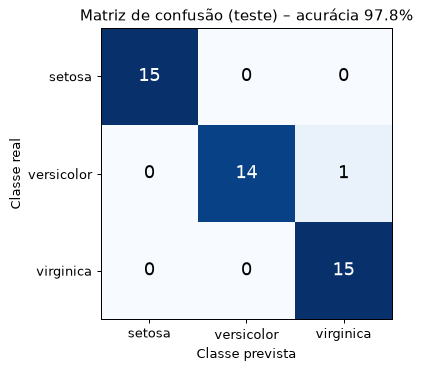

In [15]:
# Avaliação complementar: cobertura, coluna "inconclusivo", métricas por classe e treino x teste
rotulos = ["setosa", "versicolor", "virginica", "inconclusivo"]
cm = confusion_matrix(y_true, y_pred, labels=rotulos)[:3]
cm_df = pd.DataFrame(cm, index=[f"real: {c}" for c in rotulos[:3]], columns=[f"prev: {c}" for c in rotulos])

cobertura = np.mean(y_pred != "inconclusivo")
cobertos = y_pred != "inconclusivo"
acc_treino, _ = acuracia(treino)
print(f"Acurácia no TESTE:  {accuracy_score(y_true, y_pred):.3f}  ({(y_true == y_pred).sum()}/{len(y_true)})")
print(f"Acurácia no TREINO: {acc_treino:.3f}")
print(f"Cobertura no teste: {cobertura:.1%}  (casos inconclusivos: {(~cobertos).sum()})")
print(f"Acurácia entre os casos cobertos: {np.mean(y_true[cobertos] == y_pred[cobertos]):.3f}")
print("\nMatriz de confusão com a coluna 'inconclusivo':")
print(cm_df.to_string())
print("\nRelatório por classe:")
print(classification_report(y_true, y_pred, labels=rotulos[:3], digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.imshow(confusion_matrix(y_true, y_pred, labels=rotulos[:3]), cmap="Blues")
for i in range(3):
    for j in range(3):
        v = confusion_matrix(y_true, y_pred, labels=rotulos[:3])[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=14, color="white" if v > 7 else "black")
ax.set_xticks(range(3), rotulos[:3]); ax.set_yticks(range(3), rotulos[:3])
ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
ax.set_title(f"Matriz de confusão (teste) – acurácia {accuracy_score(y_true, y_pred):.1%}")
plt.tight_layout(); plt.show()

## 6. Analise os erros e aprimore seu resultado

Identifique os exemplos classificados incorretamente. Se não houver erros em alguma execução, registre isso e discuta as limitações do conjunto de teste.

In [16]:
avaliacao = teste.copy()
avaliacao["classe_prevista"] = y_pred
avaliacao["classe_real"] = y_true
avaliacao["correto"] = avaliacao["classe_real"] == avaliacao["classe_prevista"]

erros = avaliacao.loc[~avaliacao["correto"], feature_cols + ["classe_real", "classe_prevista"]]
print("Quantidade de erros:", len(erros))
erros.head(10)

Quantidade de erros: 1


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),classe_real,classe_prevista
77,6.7,3.0,5.0,1.7,versicolor,virginica


In [17]:
# Por que errou? Rastreio completo de cada erro + flores de TREINO parecidas (vizinhança na pétala)
for idx, linha in erros.iterrows():
    print("=" * 90)
    print(f"Amostra de teste {idx}")
    explicar(linha[feature_cols].to_dict(), classe_real=linha["classe_real"])
    viz = treino[(treino[PL].sub(linha[PL]).abs() <= 0.3) & (treino[PW].sub(linha[PW]).abs() <= 0.2)]
    print(f"\nFlores de treino com pétala parecida (±0,3 cm comp., ±0,2 cm larg.): {len(viz)}")
    print(viz["species"].value_counts().to_string())
    print(viz.sort_values([PL, PW]).to_string())

Amostra de teste 77
FATOS DE ENTRADA: {'comprimento da sépala': 6.7, 'largura da sépala': 3.0, 'comprimento da pétala': 5.0, 'largura da pétala': 1.7}
CADEIA DE RACIOCÍNIO:
  [A3] SE comprimento da pétala (5.0) ≥ 4.95 ENTÃO comprimento_petala = longa
  [A6] SE largura da pétala (1.7) ≥ 1.65 ENTÃO largura_petala = larga
  [R5] SE comprimento_petala = longa ENTÃO classe = virginica  [CF 0.94]
  [R6] SE largura_petala = larga ENTÃO classe = virginica  [CF 0.94]
EVIDÊNCIAS POR CLASSE: {'virginica': 0.9964}
CONFLITO ENTRE REGRAS: não
DECISÃO: virginica  (confiança 0.996)
JUSTIFICATIVA: As regras R5+R6 concordam: virginica (CF combinado 0.996).
CLASSE REAL: versicolor -> ERRO

Flores de treino com pétala parecida (±0,3 cm comp., ±0,2 cm larg.): 12
species
virginica     7
versicolor    5
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)     species
86                 6.7               3.1                4.7               1.5  versicolor
70                 5.9      

In [18]:
# Análise de conflitos e confiança no teste
res_teste = [motor_inferencia(r) for r in teste[feature_cols].to_dict("records")]
avaliacao["regras"] = [", ".join(r["activated_rules"]) for r in res_teste]
avaliacao["confianca"] = [r["confianca"] for r in res_teste]
avaliacao["conflito"] = [r["conflito"] for r in res_teste]

resumo = avaliacao.groupby("conflito").agg(casos=("correto", "size"), acertos=("correto", "sum"),
                                           confianca_media=("confianca", "mean"))
print("Desempenho com e sem conflito entre regras:")
print(resumo.round(3).to_string())
print("\nCasos de teste em que houve conflito:")
print(avaliacao.loc[avaliacao["conflito"], [PL, PW, "classe_real", "classe_prevista", "regras", "confianca"]].to_string())
print("\nPadrões de regras ativadas no teste (quantidade de flores):")
print(avaliacao["regras"].value_counts().to_string())

Desempenho com e sem conflito entre regras:
          casos  acertos  confianca_media
conflito                                 
False        40       39            0.996
True          5        5            0.940

Casos de teste em que houve conflito:
     petal length (cm)  petal width (cm) classe_real classe_prevista          regras  confianca
133                5.1               1.5   virginica       virginica  A3, A5, R4, R5       0.94
127                4.9               1.8   virginica       virginica  A2, A6, R3, R6       0.94
138                4.8               1.8   virginica       virginica  A2, A6, R3, R6       0.94
134                5.6               1.4   virginica       virginica  A3, A5, R4, R5       0.94
106                4.5               1.7   virginica       virginica  A2, A6, R3, R6       0.94

Padrões de regras ativadas no teste (quantidade de flores):
regras
A1, A4, R1, R2    15
A2, A5, R3, R4    14
A3, A6, R5, R6    11
A2, A6, R3, R6     3
A3, A5, R4, R5     2


Fração do plano (domínio das pétalas) atribuída a cada resposta: {'setosa': '20.9%', 'versicolor': '14.0%', 'virginica': '47.4%', 'inconclusivo': '17.7%'}


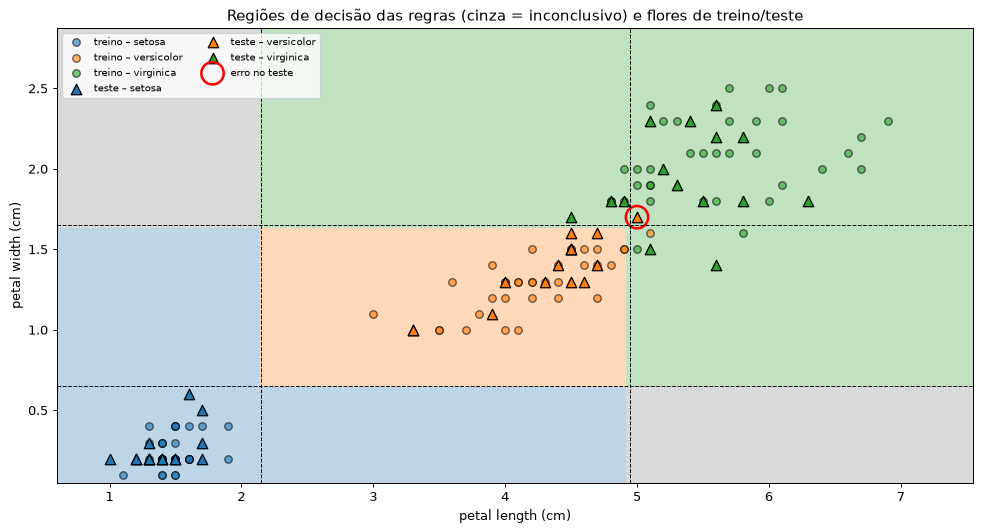

In [19]:
# Mapa de cobertura da base de conhecimento no plano das pétalas (sépalas irrelevantes quando há pétalas)
pls = np.round(np.arange(0.6, 7.6, 0.05), 3)
pws = np.round(np.arange(0.05, 2.9, 0.025), 3)
codigo = {"setosa": 0, "versicolor": 1, "virginica": 2, "inconclusivo": 3}
mapa = np.array([[codigo[motor_inferencia({PL: pl, PW: pw})["class"]] for pl in pls] for pw in pws])

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(mapa, origin="lower", aspect="auto", alpha=.3,
          extent=[pls[0], pls[-1], pws[0], pws[-1]],
          cmap=ListedColormap(["tab:blue", "tab:orange", "tab:green", "gray"]), vmin=0, vmax=3)
for especie, g in treino.groupby("species"):
    ax.scatter(g[PL], g[PW], c=cores[especie], marker="o", edgecolor="k", alpha=.6, label=f"treino – {especie}")
for especie, g in teste.groupby("species"):
    ax.scatter(g[PL], g[PW], c=cores[especie], marker="^", s=70, edgecolor="k", label=f"teste – {especie}")
ax.scatter(erros[PL], erros[PW], s=320, facecolors="none", edgecolors="red", linewidths=2, label="erro no teste")
for nome in ["PL_setosa", "PL_virginica"]:
    ax.axvline(LIMIARES[nome], ls="--", c="k", lw=.8)
for nome in ["PW_setosa", "PW_virginica"]:
    ax.axhline(LIMIARES[nome], ls="--", c="k", lw=.8)
ax.set(xlabel=PL, ylabel=PW, title="Regiões de decisão das regras (cinza = inconclusivo) e flores de treino/teste")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

frac = {k: float(np.mean(mapa == v)) for k, v in codigo.items()}
print("Fração do plano (domínio das pétalas) atribuída a cada resposta:", {k: f"{v:.1%}" for k, v in frac.items()})

In [20]:
# Ablação: quanto cada grupo de atributos contribui? (mesma base, fatos parciais, conjunto de teste)
cenarios = {
    "4 atributos (sistema completo)": feature_cols,
    "só pétalas (comprimento + largura)": [PL, PW],
    "só comprimento da pétala": [PL],
    "só largura da pétala": [PW],
    "só sépalas (regras de contingência)": [SL, SW],
}
linhas = []
for nome, atrs in cenarios.items():
    preds = np.array([motor_inferencia({c: r[c] for c in atrs})["class"] for r in teste.to_dict("records")])
    linhas.append({"cenário": nome, "acurácia (teste)": round(float(np.mean(preds == y_true)), 3),
                   "cobertura": f"{np.mean(preds != 'inconclusivo'):.0%}"})
pd.DataFrame(linhas)

,cenário,acurácia (teste),cobertura
0,4 atributos (sistema completo),0.978,100%
1,só pétalas (comprimento + largura),0.978,100%
2,só comprimento da pétala,0.911,100%
3,só largura da pétala,0.933,100%
4,só sépalas (regras de contingência),0.711,100%


In [21]:
# Sensibilidade dos limiares versicolor x virginica (transparência sobre a fragilidade da fronteira)
# A escolha oficial foi feita SÓ pelo treino; aqui mostramos o que aconteceria no teste com outras escolhas.
linhas = []
for tpl in [4.75, 4.85, 4.95, 5.05, 5.15]:
    for tpw in [1.45, 1.55, 1.65, 1.75, 1.85]:
        L = {**LIMIARES, "PL_virginica": tpl, "PW_virginica": tpw}
        base = com_cf(regras, calibrar_cf(treino, regras, L))
        acc_tr, _ = acuracia(treino, base, L)
        acc_te, _ = acuracia(teste, base, L)
        linhas.append({"PL_virginica": tpl, "PW_virginica": tpw,
                       "erros treino": int(round((1 - acc_tr) * len(treino))),
                       "erros teste": int(round((1 - acc_te) * len(teste)))})
sens = pd.DataFrame(linhas)
print("Erros no TREINO (critério usado para escolher):")
print(sens.pivot(index="PL_virginica", columns="PW_virginica", values="erros treino").to_string())
print("\nErros no TESTE (apenas para análise, não usado na escolha):")
print(sens.pivot(index="PL_virginica", columns="PW_virginica", values="erros teste").to_string())

Erros no TREINO (critério usado para escolher):
PW_virginica  1.45  1.55  1.65  1.75  1.85
PL_virginica                              
4.75             4     3     3     3     5
4.85             4     3     4     4     4
4.95             4     3     2     2     3
5.05             7     3     3     3     4
5.15             9     3     2     2     4

Erros no TESTE (apenas para análise, não usado na escolha):
PW_virginica  1.45  1.55  1.65  1.75  1.85
PL_virginica                              
4.75             3     4     4     3     2
4.85             4     5     5     4     3
4.95             5     5     1     2     4
5.05             4     5     1     1     3
5.15             7     4     2     2     4


In [22]:
# Robustez da METODOLOGIA: repetimos a aquisição de conhecimento (limiares + CFs) em 20 divisões diferentes
# e avaliamos cada base nas respectivas flores de teste. Mede se o procedimento generaliza, não só esta divisão.
resultados = []
for seed in range(20):
    tr, te = train_test_split(df, test_size=0.3, random_state=seed, stratify=df["species"])
    lim, cal, _ = adquirir_conhecimento(tr)
    base = com_cf(regras, cal)
    acc_te, pred = acuracia(te, base, lim)
    resultados.append({"random_state": seed, "PL_virginica": lim["PL_virginica"],
                       "PW_virginica": lim["PW_virginica"], "acurácia teste": round(acc_te, 3),
                       "inconclusivos": int(np.sum(np.array(pred) == "inconclusivo"))})
rob = pd.DataFrame(resultados)
print(f"Acurácia média em 20 divisões: {rob['acurácia teste'].mean():.3f} ± {rob['acurácia teste'].std():.3f} "
      f"(mín. {rob['acurácia teste'].min():.3f}, máx. {rob['acurácia teste'].max():.3f})")
print("Total de casos inconclusivos em 20 x 45 flores de teste:", rob["inconclusivos"].sum())
rob

Acurácia média em 20 divisões: 0.974 ± 0.021 (mín. 0.933, máx. 1.000)
Total de casos inconclusivos em 20 x 45 flores de teste: 0


,random_state,PL_virginica,PW_virginica,acurácia teste,inconclusivos
0,0,4.85,1.65,0.956,0
1,1,4.95,1.65,1.000,0
2,2,4.95,1.65,1.000,0
3,3,4.95,1.65,0.956,0
4,4,4.95,1.65,0.978,0
5,5,4.95,1.65,0.956,0
6,6,4.95,1.75,0.956,0
7,7,4.95,1.75,0.956,0
8,8,5.15,1.65,0.933,0
9,9,4.95,1.65,0.978,0


### 6.1 Análise dos resultados

**Desempenho na divisão oficial (`test_size=0.3`, `random_state=42`)**

| Métrica | Valor |
|---|---|
| Acurácia no teste | **97,8 % (44 de 45)** |
| Acurácia no treino | 98,1 % (103 de 105) |
| Cobertura no teste | **100 %** (nenhum caso inconclusivo) |
| Erros | 1 (versicolor classificada como virginica) |
| Robustez da metodologia (20 divisões) | 97,4 % ± 2,1 % (mín. 93,3 %, máx. 100 %) |

A diferença entre treino (98,1 %) e teste (97,8 %) é mínima, o que indica que as regras **não decoraram** o treino: são apenas 6 regras de classificação principais, com limiares gerais, e nenhuma foi criada para uma amostra específica.

**Matriz de confusão (teste):** setosa 15/15; versicolor 14/15; virginica 15/15. A setosa é separada com folga (há um vão de mais de 1 cm no comprimento da pétala); todos os riscos estão na fronteira versicolor × virginica.

**Análise do único erro (amostra 77: pétala 5,0 × 1,7 cm, real versicolor → prevista virginica)**
- A flor tem pétala **longa** (5,0 ≥ 4,95) **e larga** (1,7 ≥ 1,65): as duas regras disparadas (R5 e R6) concordam em virginica, sem conflito. Para as regras ela é uma virginica típica.
- Entre as 12 flores de treino com pétala parecida (±0,3 cm × ±0,2 cm), **7 são virginica e 5 versicolor**. A maioria da vizinhança é virginica, então a decisão é a mais coerente com o conhecimento disponível. A flor é um **caso atípico de versicolor**, que nenhuma regra geral baseada em limiares acertaria sem errar outras flores.
- Corrigir esse caso exigiria uma regra específica para ele (ex.: "pétala entre 4,95 e 5,05 com largura 1,7 → versicolor"), o que seria *overfitting* e é justamente o que o enunciado pede para evitar.

**Conflitos entre regras:** 5 das 45 flores de teste (11 %) geraram conflito (pétala média + larga, ou longa + largura média). Todos os 5 foram resolvidos corretamente pelos fatores de certeza, sempre a favor de virginica. Os casos com conflito têm confiança menor (0,94 contra 0,996 dos casos sem conflito). Ou seja, **o próprio sistema sinaliza quando a decisão é menos segura**. A amostra 106 (pétala 4,5 × 1,7, rastreada na seção 4) é o exemplo mais interessante: o comprimento "parece" versicolor, mas a largura, mais confiável nessa faixa, decide corretamente por virginica.

**Casos sem cobertura**
- No teste oficial **não houve nenhum caso inconclusivo**, nem nas 20 divisões extras (0 em 900 classificações): as regras A1–A6 particionam todo o domínio das pétalas, então toda flor real recebe uma resposta.
- O mapa de regiões mostra que ~18 % do plano das pétalas resulta em `inconclusivo`. São as regiões **pétala curta + larga** e **pétala longa + estreita**, combinações biologicamente incoerentes e sem nenhuma flor no dataset. Nessas regiões é melhor não arriscar (provável erro de medição) do que adivinhar.
- Com **fatos incompletos**, a cobertura é mantida: um só atributo da pétala basta (91–93 % de acurácia); sem pétalas, as regras de contingência por sépala respondem com 71 % de acurácia e CF baixo, avisando o usuário da incerteza. Valores inválidos ou absurdos são descartados (V1/V2) sem derrubar o sistema; só quando **nenhum** fato válido resta a resposta é `inconclusivo`.

**Ablação (contribuição dos atributos):** pétalas = 97,8 %; só comprimento = 91,1 %; só largura = 93,3 %; só sépalas = 71,1 %. As sépalas não acrescentam acurácia quando as pétalas existem, por isso entram apenas como contingência. Combinar comprimento e largura da pétala é o que permite resolver os casos de fronteira.

**Limitações identificadas**
1. **Fronteira frágil:** a análise de sensibilidade mostra que deslocar um limiar em 0,1 cm muda de 1 para até 5 erros no teste. As duas flores de teste com largura 1,7 (77 e 106) caem exatamente na faixa sem dados de treino (entre 1,6 e 1,8), então o resultado depende de onde o limiar é posto nesse "vão". A escolha (1,65) foi feita só pelo critério do treino, mas a sensibilidade deixa claro que **com 45 flores de teste, cada erro vale 2,2 pontos percentuais**, e a diferença entre 95 % e 98 % pode ser sorte da divisão. A média em 20 divisões (97,4 %) é a estimativa mais confiável.
2. **Fronteiras retangulares:** as regras só cortam um atributo de cada vez (eixos paralelos). A separação real entre versicolor e virginica é diagonal (combinação de comprimento e largura), o que regras com um único limiar não capturam bem.
3. **Conjunto pequeno:** 35 flores por classe no treino; os CFs (ex.: 0,94) são estimados com poucos exemplos e mudariam com mais dados.
4. **Conhecimento estático:** se surgirem novas espécies ou medições de outra população, as regras precisam ser revisadas manualmente por um especialista.

## Entrega da equipe
**Integrantes:** Mateus Ferreira da Silva, Rhyan Mezaroba, Thiago Balbinot e Thiago Thomasi

- [x] Regras documentadas em linguagem natural (seção 2.4).
- [x] Acurácia e matriz de confusão (seção 5, `test_size=0.3`, `random_state=42`).
- [x] Análise de erros e casos sem cobertura (seções 3.1 e 6).

**Reflexão:** em quais situações uma base de regras explícitas pode ser insuficiente e seria interessante experimentar Machine Learning?

**Resposta:** no Iris, poucas regras explícitas chegaram a 97,8 % de acurácia com explicação completa de cada decisão, porque o problema tem poucos atributos e fronteiras quase alinhadas aos eixos. Regras explícitas passam a ser insuficientes quando:
- **há muitos atributos ou interações complexas** (ex.: imagens, texto, sinais), e escrever e manter regras à mão fica inviável ou contraditório;
- **as fronteiras entre classes são não lineares ou diagonais**, como a região de sobreposição versicolor × virginica, que limiares sobre um atributo por vez só aproximam;
- **não existe um especialista** capaz de articular o conhecimento, ou o conhecimento é tácito (o especialista "sabe", mas não consegue explicar como);
- **os dados mudam com o tempo** (novas populações, novas classes), e a base precisaria de revisão manual constante; um modelo de ML pode ser re-treinado automaticamente;
- **há grande volume de dados rotulados**, que um algoritmo aproveita melhor do que a análise humana.

Por outro lado, o sistema especialista continua vantajoso quando **explicabilidade, auditabilidade e controle** são essenciais (saúde, crédito, normas legais) ou quando há poucos dados. Uma abordagem **híbrida** também é interessante: usar ML (ex.: uma árvore de decisão) para *sugerir* limiares e regras, que o especialista revisa, valida e incorpora à base de conhecimento.